# ChebND 
## 1-Dimensional Interpolation

In [1]:
from chebND.interp1d import ChebyshevInterpolant1D, compute_chebyshev_coefficients_1d
from chebND.clenshaw import clenshaw_1d
from chebND.utils import chebyshev_nodes, chebyshev_gauss_lobatto_nodes
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct

In [2]:
# Define function and domain
f = lambda x: np.exp(-x**2) 

In [34]:
a = -2
b = 2
N = 21  

In [35]:
x_nodes = chebyshev_nodes(N,a,b)
vals = f(x_nodes) 
interp1 = ChebyshevInterpolant1D(vals, a=a, b=b, N=N,kind = "nodes")

coeffs1 = interp1.get_coefficients()
print(coeffs1)

[ 3.08508323e-01 -1.92280008e-17 -4.30538578e-01  3.89501244e-17
  1.86478067e-01  3.65337411e-18 -5.75824453e-02  2.20247927e-17
  1.37307308e-02 -2.38730993e-17 -2.65952219e-03  3.48596813e-17
  4.33119831e-04 -3.17206578e-17 -6.08032071e-05  3.17206578e-17
  7.49745071e-06 -7.40148683e-17 -8.24581650e-07  4.22942105e-17
  8.90285327e-08]


In [36]:
x_GL = chebyshev_gauss_lobatto_nodes(N,a,b)
vals2 = f(x_GL)
interp2 = ChebyshevInterpolant1D(vals2, a=a, b=b, N=N, kind = "GL")

coeffs2 = interp2.get_coefficients()
print(coeffs2)

[ 3.08508323e-01 -3.29074491e-17 -4.30538578e-01  4.54470921e-17
  1.86478067e-01 -2.68031548e-17 -5.75824453e-02  5.41512347e-18
  1.37307308e-02 -4.24808907e-17 -2.65952219e-03  4.78486135e-17
  4.33119834e-04 -3.90995947e-17 -6.08032505e-05  4.59869434e-18
  7.49801416e-06 -1.17626209e-17 -8.31339723e-07  1.64374960e-17
  8.16603322e-08]


In [37]:
coeffs2[0]/coeffs1[0]

np.float64(1.0)

In [38]:
coeffs2[-1]/coeffs1[-1]

np.float64(0.9172377631979292)

In [39]:
2* (N-1)

40

In [40]:
x_test = np.linspace(-2, 2, 1000)
y_interp = interp1.evaluate(x_test)
y_interp2 = interp2.evaluate(x_test)
y_vals = f(x_test)

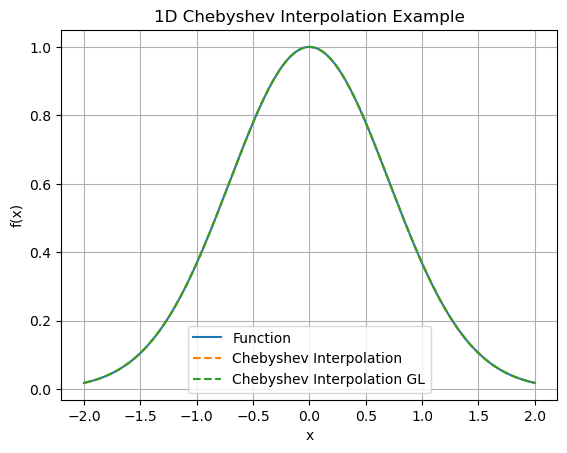

In [41]:
# Plotting the results
plt.plot(x_test, y_vals, label='Function')
plt.plot(x_test, y_interp, label='Chebyshev Interpolation', linestyle='--')
plt.plot(x_test, y_interp2, label='Chebyshev Interpolation GL', linestyle='--')
plt.legend()
plt.title('1D Chebyshev Interpolation Example')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

In [42]:
estAbsErr = interp1.absolute_error()
estRelErr = interp1.relative_error()

print(f"Estimated Absolute Error: {estAbsErr}")
print(f"Estimated Relative Error: {estRelErr}")

Estimated Absolute Error: 8.902853273817866e-08
Estimated Relative Error: 2.0678410062297825e-07


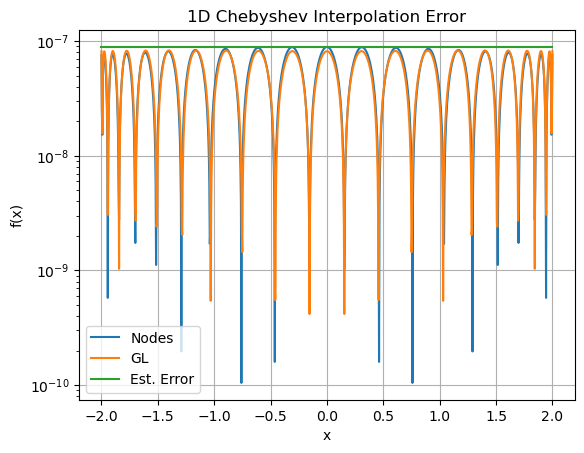

In [43]:
# Plotting the results
plt.plot(x_test, abs(y_vals - y_interp), label='Nodes')
plt.plot(x_test, abs(y_vals - y_interp2), label='GL')
plt.plot(x_test, np.ones_like(x_test) * estAbsErr, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()

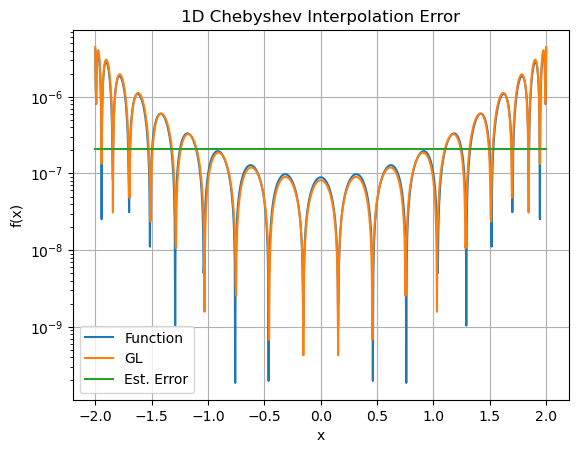

In [44]:
# Plotting the results
plt.plot(x_test, abs((y_vals - y_interp)/y_vals), label='Function')
plt.plot(x_test, abs((y_vals - y_interp2)/y_vals), label='GL')
plt.plot(x_test, np.ones_like(x_test) * estRelErr, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()

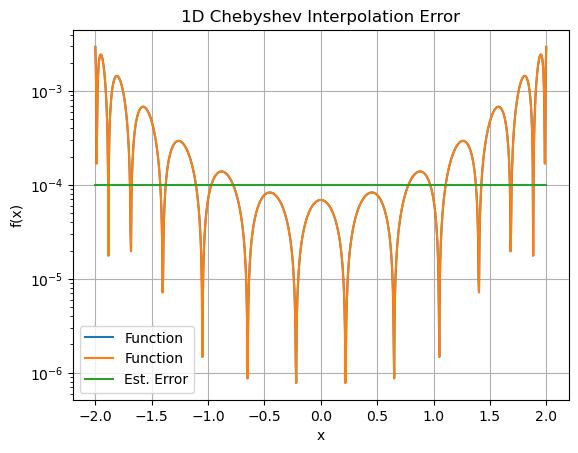

In [45]:
delta = 1e-4
interp1.optimize(rel_tol=delta)
y_interp = interp1.evaluate(x_test)
interp2.optimize(rel_tol=delta)
y_interp2 = interp2.evaluate(x_test)
# Plotting the results
plt.plot(x_test, abs((y_vals - y_interp)/y_vals), label='Function')
plt.plot(x_test, abs((y_vals - y_interp2)/y_vals), label='Function')
plt.plot(x_test, np.ones_like(x_test) * delta, label='Est. Error')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()